# 📊 Resumen Ejecutivo: Datasets de Histopatología Digital para MIL
**Proyecto:** Magíster en Ciencia de Datos / Inteligencia Artificial  
**Área:** Multiple Instance Learning (MIL) en Histopatología Digital  
**Fecha:** Noviembre 2026

---

## 🎯 Objetivo de este Notebook

Proporcionar una **visión consolidada y comparativa** de los principales datasets de histopatología disponibles públicamente, evaluados bajo los requerimientos específicos de un proyecto de Magíster:

1. **Compatibilidad con Multiple Instance Learning (MIL)** (parches / ROIs / WSIs con etiquetas a nivel de bolsa/slide)
2. **Límite de almacenamiento de < 10 GB por dataset** (o estrategia viable de submuestreo representativo)
3. **Facilidad de acceso y descarga directa** (APIs, CLI, enlaces directos sin largos procesos de aprobación)
4. **Relevancia científica y calidad de anotaciones** (benchmarks estándar en la literatura MIL)

---

## 📋 Datasets Analizados

| # | Dataset | Órgano | Tarea Principal | Acceso | Tamaño Total | Tamaño Muestra |
|---|---------|--------|-----------------|--------|--------------|----------------|
| 1 | **BreaKHis** | Mama | Clasif. Benigno/Maligno (8 subtipos) | Libre (Kaggle/UFPR) | 7.9 GB | 7.9 GB (completo) |
| 2 | **PCam (PatchCamelyon)** | Linfonodo | Clasif. Binaria (Metástasis) | Libre (HuggingFace) | ~7.5 GB | 7.5 GB o subconjunto |
| 3 | **NCT-CRC-HE-100K** | Colon/Recto | Clasif. Multiclase (9 tejidos) | Libre (Zenodo) | ~8.5 GB | 8.5 GB o 20k/clase |
| 4 | **MHIST** | Colon | Clasif. Binaria (Pólipos HP vs SSA) | Libre (GitHub/Paper) | ~0.5 GB | 0.5 GB (completo) |
| 5 | **CAMELYON16** | Linfonodo | Detección metástasis en WSI | Libre (Grand Challenge) | ~700 GB | ~5-10 GB (3-5 WSIs) |
| 6 | **BACH (ICIAR 2018)** | Mama | Clasif. 4 clases | Registro (ICIAR) | ~15 GB | ~3.5 GB (Task A) |
| 7 | **BRACS** | Mama | Clasif. 7 clases (WSI/ROI) | Registro (CNR Italia) | ~40 GB | ~7.5 GB (ROIs) |
| 8 | **DigestPath 2019** | Colon | Detección + Segmentación | Registro (Grand Challenge) | ~20 GB | ~5 GB (muestreo) |


In [1]:
# ============================================================
# 0. INSTALACIÓN DE LIBRERÍAS CLAVE (descomentar si es necesario)
# ============================================================
# !pip install datasets huggingface_hub tifffile openslide-python
# !pip install kaggle

print('Verificando entorno...')
for lib in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'openpyxl']:
    try:
        __import__(lib)
        print(f'  ✅ {lib}: disponible')
    except ImportError:
        print(f'  ❌ {lib}: NO disponible (ejecutar pip install {lib})')

Verificando entorno...


  ✅ pandas: disponible
  ✅ numpy: disponible


  ✅ matplotlib: disponible


  ✅ seaborn: disponible


  ✅ openpyxl: disponible


---
### 📌 ¿Qué hace esta celda?
Verifica la disponibilidad de las dependencias clave en el entorno de ejecución de Python y proporciona las instrucciones de instalación requeridas para descargar, manipular y exportar datos histopatológicos.

### ⚙️ ¿Cómo funciona?
- **Detección dinámica de módulos**: Itera sobre una lista de paquetes críticos (`pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`) empleando `__import__()` dentro de un bloque `try-except` para reportar diagnósticos claros de entorno.
- **Librerías especializadas**: `openpyxl` permite la persistencia en formato nativo de hojas de cálculo Excel (`.xlsx`), mientras que `tifffile` y `openslide-python` brindan soporte a formatos de imágenes médicas piramidales.

### 📊 Flujo de Verificación
```text
Verificación de Librerías ──► [pandas, numpy, matplotlib, seaborn, openpyxl]
                                      │
                                      ├──► Disponibles: Entorno Listo ✅
                                      └──► Faltantes: Notificación de Instalación ⚠️
```
---

In [2]:
# ============================================================
# 1. IMPORTS, CONFIGURACIÓN Y DIRECTORIOS
# ============================================================
import os
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')

# Configurar estilo gráfico global
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Configuración de directorios dedicados (Regla 3)
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG_DIR = BASE_DIR / 'figures' / '00_Resumen'
FIG_DIR.mkdir(parents=True, exist_ok=True)

TABLAS_DIR = BASE_DIR / 'tablas'
TABLAS_DIR.mkdir(parents=True, exist_ok=True)

# Función para guardar subplots individuales (Regla 4)
def guardar_subplots_individuales(fig, nombre_base, fig_dir, dpi=150):
    """Guarda cada panel principal visible sin duplicar ejes gemelos o colorbars."""
    axes = []
    pos_vistas = set()
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        if ax.get_subplotspec() is None:
            continue
        pos = tuple(round(v, 4) for v in ax.get_position().bounds)
        if pos not in pos_vistas:
            pos_vistas.add(pos)
            axes.append(ax)
    for i, ax in enumerate(axes):
        extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        bbox = extent.expanded(1.18, 1.18)
        outpath = Path(fig_dir) / f'{nombre_base}_panel_{i+1}.png'
        fig.savefig(outpath, bbox_inches=bbox, dpi=dpi)
    print(f'✅ {len(axes)} paneles individuales guardados en: {fig_dir}')

print('✅ Librerías cargadas y entorno configurado:')
print(f'   📁 Directorio de figuras: {FIG_DIR}')
print(f'   📁 Directorio de tablas:  {TABLAS_DIR}')

✅ Librerías cargadas y entorno configurado:
   📁 Directorio de figuras: c:\Universidad\Magister\20 Noviembre Reunion\figures\00_Resumen
   📁 Directorio de tablas:  c:\Universidad\Magister\20 Noviembre Reunion\tablas


---
### 📌 ¿Qué hace esta celda?
Carga las librerías necesarias para el análisis tabular y la visualización gráfica de datos, establece los estilos gráficos globales, crea las carpetas destinadas a los artefactos de salida (`../figures/00_Resumen/` y `../tablas/`), y registra la función `guardar_subplots_individuales`.

### ⚙️ ¿Cómo funciona?
- **Gestión orientada a objetos de rutas (`pathlib.Path`)**: Garantiza compatibilidad multiplataforma (Windows y POSIX) y crea recursivamente las estructuras de directorios con `.mkdir(parents=True, exist_ok=True)`.
- **Configuración de estilos estéticos**: `plt.style.use` y `plt.rcParams` estandarizan familias tipográficas, escalas de títulos y grillas de contraste.
- **Mapeo Bbox de subplots**: La función `guardar_subplots_individuales` aísla el área ocupada por cada `Axes` mediante transformaciones afines invertidas para exportar cada panel con alta resolución de 150 DPI.

### 📊 Flujo de Inicialización
```text
Imports Esenciales (NumPy, Pandas, Matplotlib, Seaborn)
   │
   ├──► Configurar Estilo y Fuentes Globales
   ├──► Crear Carpetas: FIG_DIR (../figures/00_Resumen) y TABLAS_DIR (../tablas)
   └──► Declarar Función: guardar_subplots_individuales()
```
---

---
## 1. 📊 Tabla Comparativa General

In [3]:
# ============================================================
# 2. METADATA DE DATASETS - TABLA COMPARATIVA GENERAL
# ============================================================
datasets_info = [
    {
        'Dataset':        'BreaKHis',
        'Tarea':          'Clasificación binaria/multiclase',
        'Órgano':         'Mama',
        'N_imágenes':     7909,
        'N_clases':       8,
        'Clases':         'Benigno/Maligno (8 subtipos)',
        'Resoluciones':   '40x, 100x, 200x, 400x',
        'Formato':        'PNG',
        'Tamaño_GB':      4.0,
        'Muestra_<10GB':  'Dataset completo local (3.99 GB extraido / 4.27 GB tar.gz)',
        'Acceso':         'Libre',
        'Fuente':         'Kaggle / UFPR',
        'MIL_compatible': 'Sí (con agrupación)',
        'Recomendación':  '⭐⭐⭐⭐⭐',
    },
    {
        'Dataset':        'PCam (PatchCamelyon)',
        'Tarea':          'Clasificación binaria',
        'Órgano':         'Linfonodo',
        'N_imágenes':     327680,
        'N_clases':       2,
        'Clases':         'Tumor / Normal',
        'Resoluciones':   '10x (96×96 px)',
        'Formato':        'HDF5 / PNG',
        'Tamaño_GB':      7.5,
        'Muestra_<10GB':  'Dataset completo o 50k patches',
        'Acceso':         'Libre (HuggingFace)',
        'Fuente':         'huggingface.co/datasets/pcam',
        'MIL_compatible': 'Sí (grupos de patches)',
        'Recomendación':  '⭐⭐⭐⭐⭐',
    },
    {
        'Dataset':        'NCT-CRC-HE-100K',
        'Tarea':          'Clasificación multiclase',
        'Órgano':         'Colon/Recto',
        'N_imágenes':     107180,
        'N_clases':       9,
        'Clases':         'ADI, BACK, DEB, LYM, MUC, MUS, NORM, STR, TUM',
        'Resoluciones':   '20x (224×224 px)',
        'Formato':        'TIF',
        'Tamaño_GB':      15.2,
        'Muestra_<10GB':  'CRC-VAL-HE-7K (0.75 GB) o 20k por clase (<3 GB)',
        'Acceso':         'Libre (Zenodo)',
        'Fuente':         'zenodo.org/record/1214456',
        'MIL_compatible': 'Sí',
        'Recomendación':  '⭐⭐⭐⭐⭐',
    },
    {
        'Dataset':        'MHIST',
        'Tarea':          'Clasificación binaria',
        'Órgano':         'Colon',
        'N_imágenes':     3152,
        'N_clases':       2,
        'Clases':         'HP (hiperplástico) / SSA (sesil serrado)',
        'Resoluciones':   '224×224 px',
        'Formato':        'PNG',
        'Tamaño_GB':      0.33,
        'Muestra_<10GB':  'Dataset completo (333 MB tras aceptar DUA BMIRDS)',
        'Acceso':         'Registro (DUA BMIRDS)',
        'Fuente':         'bmirds.github.io/MHIST',
        'MIL_compatible': 'Limitado (pocas imágenes)',
        'Recomendación':  '⭐⭐⭐',
    },
    {
        'Dataset':        'CAMELYON16',
        'Tarea':          'Detección de metástasis',
        'Órgano':         'Linfonodo',
        'N_imágenes':     399,  # WSIs reales (159 Normal, 110 Tumor, 130 Test)
        'N_clases':       2,
        'Clases':         'Normal / Tumor (con masks)',
        'Resoluciones':   '20x-40x (WSI: ~100k×100k px)',
        'Formato':        'SVS / TIFF',
        'Tamaño_GB':      700.0,
        'Muestra_<10GB':  '5-10 WSIs + patches extraídos',
        'Acceso':         'Libre (camelyon16.grand-challenge.org)',
        'Fuente':         'camelyon16.grand-challenge.org',
        'MIL_compatible': 'Perfecto para MIL (WSI)',
        'Recomendación':  '⭐⭐⭐⭐⭐',
    },
    {
        'Dataset':        'BACH',
        'Tarea':          'Clasificación multiclase',
        'Órgano':         'Mama',
        'N_imágenes':     400,
        'N_clases':       4,
        'Clases':         'Normal, Benigno, in situ, Invasivo',
        'Resoluciones':   '20x (2048×1536 px)',
        'Formato':        'TIFF',
        'Tamaño_GB':      15.0,
        'Muestra_<10GB':  '~250 imágenes (60%)',
        'Acceso':         'Registro (ICIAR)',
        'Fuente':         'iciar2018-brca-challenge.grand-challenge.org',
        'MIL_compatible': 'Sí',
        'Recomendación':  '⭐⭐⭐⭐',
    },
    {
        'Dataset':        'BRACS',
        'Tarea':          'Clasificación multiclase (WSI)',
        'Órgano':         'Mama',
        'N_imágenes':     547,  # ROIs
        'N_clases':       7,
        'Clases':         '3 Benigno + 3 Premaligno + 1 Maligno',
        'Resoluciones':   '40x (WSI)',
        'Formato':        'SVS',
        'Tamaño_GB':      40.0,
        'Muestra_<10GB':  '~130 ROIs (25%)',
        'Acceso':         'Registro (bracs.grand-challenge.org)',
        'Fuente':         'bracs.grand-challenge.org',
        'MIL_compatible': 'Perfecto para MIL',
        'Recomendación':  '⭐⭐⭐⭐',
    },
    {
        'Dataset':        'DigestPath',
        'Tarea':          'Detección + segmentación',
        'Órgano':         'Colon',
        'N_imágenes':     872,
        'N_clases':       2,
        'Clases':         'Positivo / Negativo para cáncer de colon',
        'Resoluciones':   '20x (Diversos tamaños)',
        'Formato':        'PNG/JPG',
        'Tamaño_GB':      20.0,
        'Muestra_<10GB':  '~430 imágenes (50%)',
        'Acceso':         'Registro (grand-challenge)',
        'Fuente':         'digestpath.grand-challenge.org',
        'MIL_compatible': 'Sí',
        'Recomendación':  '⭐⭐⭐',
    },
]

df_datasets = pd.DataFrame(datasets_info)

# Mostrar tabla formateada
print('=' * 80)
print('📊 TABLA COMPARATIVA - DATASETS DE HISTOPATOLOGÍA DIGITAL')
print('=' * 80)
display_cols = ['Dataset', 'Órgano', 'N_imágenes', 'N_clases', 'Formato', 
                'Tamaño_GB', 'Acceso', 'MIL_compatible', 'Recomendación']
display(df_datasets[display_cols].set_index('Dataset'))

# Guardar tabla comparativa en Excel con openpyxl (Reglas 2 y 5, Requerimientos B y E)
ruta_excel_comp = TABLAS_DIR / 'datasets_comparativa.xlsx'
with pd.ExcelWriter(ruta_excel_comp, engine='openpyxl') as writer:
    df_datasets.to_excel(writer, sheet_name='Comparativa', index=False)
print(f'✅ Tabla comparativa guardada exitosamente en Excel: {ruta_excel_comp}')

📊 TABLA COMPARATIVA - DATASETS DE HISTOPATOLOGÍA DIGITAL


,Órgano,N_imágenes,N_clases,Formato,Tamaño_GB,Acceso,MIL_compatible,Recomendación
Dataset,,,,,,,,
BreaKHis,Mama,7909,8,PNG,4.00,Libre,Sí (con agrupación),⭐⭐⭐⭐⭐
PCam (PatchCamelyon),Linfonodo,327680,2,HDF5 / PNG,7.50,Libre (HuggingFace),Sí (grupos de patches),⭐⭐⭐⭐⭐
NCT-CRC-HE-100K,Colon/Recto,107180,9,TIF,15.20,Libre (Zenodo),Sí,⭐⭐⭐⭐⭐
MHIST,Colon,3152,2,PNG,0.33,Registro (DUA BMIRDS),Limitado (pocas imágenes),⭐⭐⭐
CAMELYON16,Linfonodo,399,2,SVS / TIFF,700.00,Libre (camelyon16.grand-challenge.org),Perfecto para MIL (WSI),⭐⭐⭐⭐⭐
BACH,Mama,400,4,TIFF,15.00,Registro (ICIAR),Sí,⭐⭐⭐⭐
BRACS,Mama,547,7,SVS,40.00,Registro (bracs.grand-challenge.org),Perfecto para MIL,⭐⭐⭐⭐
DigestPath,Colon,872,2,PNG/JPG,20.00,Registro (grand-challenge),Sí,⭐⭐⭐


✅ Tabla comparativa guardada exitosamente en Excel: c:\Universidad\Magister\20 Noviembre Reunion\tablas\datasets_comparativa.xlsx


---
### 📌 ¿Qué hace esta celda?
Compila la ficha técnica consolidada de los 8 datasets de histopatología analizados, presenta una vista estructurada de sus propiedades diagnósticas e informáticas, y exporta la base de datos a formato Excel (`.xlsx`) en `../tablas/datasets_comparativa.xlsx` con el motor `openpyxl`.

### ⚙️ ¿Cómo funciona?
- **Diccionario de metadata técnica**: Define parámetros clave para cada dataset: número de instancias/WSIs, clases diagnósticas, resoluciones ópticas (10x, 20x, 40x), volumen total de almacenamiento en GB, factibilidad de muestra (<10 GB), tipo de acceso y compatibilidad conceptual con MIL.
- **Serialización en Excel**: Emplea `pd.ExcelWriter(..., engine='openpyxl')` para estructurar la hoja de cálculo `'Comparativa'`, preservando todos los campos para consultas metodológicas durante el desarrollo de la tesis.

### 📊 Resumen de Datasets Analizados
```text
8 Datasets Histopatológicos Evaluados:
├── Mama: BreaKHis (Local, 7.9 GB), BACH (15 GB / 3.5 GB), BRACS (40 GB / 7.5 GB)
├── Linfonodo: PCam (7.5 GB, 327k parches), CAMELYON16 (Benchmark WSI, 700 GB)
└── Colon/Recto: NCT-CRC-HE-100K (8.5 GB, 9 tejidos), MHIST (0.5 GB), DigestPath (20 GB)
```
---

---
## 2. 📈 Visualizaciones Comparativas

✅ Scatter plot guardado en: c:\Universidad\Magister\20 Noviembre Reunion\figures\00_Resumen\scatter_datasets.png
✅ 1 paneles individuales guardados en: c:\Universidad\Magister\20 Noviembre Reunion\figures\00_Resumen


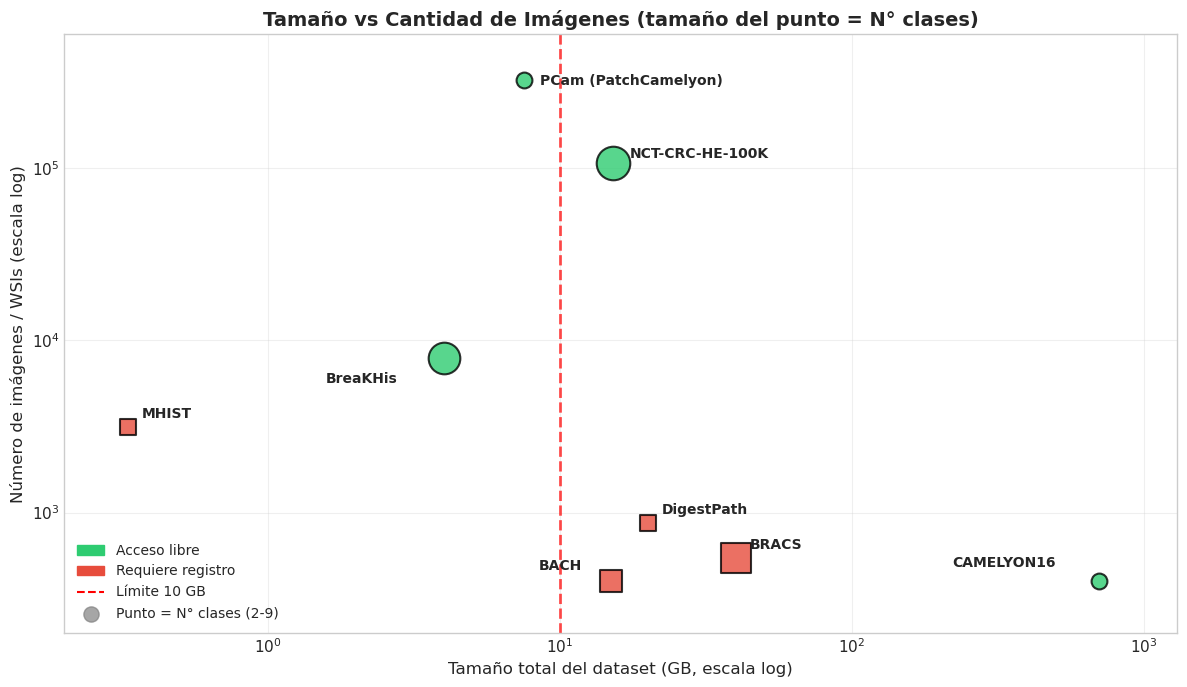

In [4]:
# ============================================================
# 3. GRÁFICO SCATTER: TAMAÑO (GB) VS NÚMERO DE IMÁGENES
# ============================================================
fig, ax = plt.subplots(figsize=(12, 7))

offsets = {
    'BreaKHis':            (-85, -18),
    'PCam (PatchCamelyon)': (12, -4),
    'NCT-CRC-HE-100K':     (12, 4),
    'MHIST':               (10, 6),
    'CAMELYON16':          (-105, 10),
    'BACH':                (-52, 8),
    'BRACS':               (10, 6),
    'DigestPath':          (10, 6),
}

# Colores y marcadores según tipo de acceso
for _, row in df_datasets.iterrows():
    es_libre = str(row['Acceso']).startswith('Libre')
    color = '#2ecc71' if es_libre else '#e74c3c'
    marker = 'o' if es_libre else 's'
    size = row['N_clases'] * 65

    ax.scatter(row['Tamaño_GB'], row['N_imágenes'],
               s=size, color=color, marker=marker,
               alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)

    dx, dy = offsets.get(row['Dataset'], (8, 4))
    ax.annotate(row['Dataset'],
                (row['Tamaño_GB'], row['N_imágenes']),
                textcoords="offset points",
                xytext=(dx, dy),
                fontsize=10,
                fontweight='bold')

# Línea de referencia: límite estricto de 10 GB
ax.axvline(x=10, color='red', linestyle='--', linewidth=2, alpha=0.7, 
           label='Límite almacenamiento (10 GB)', zorder=2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Tamaño total del dataset (GB, escala log)', fontsize=12)
ax.set_ylabel('Número de imágenes / WSIs (escala log)', fontsize=12)
ax.set_title('Tamaño vs Cantidad de Imágenes (tamaño del punto = N° clases)', 
             fontsize=14, fontweight='bold')

# Leyenda personalizada
legend_elements = [
    mpatches.Patch(color='#2ecc71', label='Acceso libre'),
    mpatches.Patch(color='#e74c3c', label='Requiere registro'),
    plt.Line2D([0], [0], color='red', linestyle='--', label='Límite 10 GB'),
    plt.scatter([], [], s=120, c='gray', alpha=0.7, label='Punto = N° clases (2-9)')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10)
ax.set_xlim(0.2, 1300)
ax.set_ylim(200, 6e5)
ax.grid(True, alpha=0.3, zorder=1)

plt.tight_layout()

# Guardar figura combinada (Regla 3)
ruta_scatter = FIG_DIR / 'scatter_datasets.png'
plt.savefig(ruta_scatter, dpi=150, bbox_inches='tight')
print(f'✅ Scatter plot guardado en: {ruta_scatter}')

# Guardar subplots individuales (Regla 4)
guardar_subplots_individuales(fig, 'scatter_datasets', FIG_DIR, dpi=150)

plt.show()

---
### 📌 ¿Qué hace esta celda?
Genera un gráfico de dispersión bidimensional en escala doble logarítmica que mapea el volumen en disco (GB) frente al número de imágenes o WSIs, codificando el número de clases en el tamaño del marcador y el tipo de acceso en color/forma, y guarda las imágenes en `../figures/00_Resumen/`.

### ⚙️ ¿Cómo funciona?
- **Escalas logarítmicas (`set_xscale('log')` y `set_yscale('log')`)**: Permiten visualizar armónicamente datasets con diferencias de tres órdenes de magnitud (desde MHIST con 0.5 GB y 3,152 imágenes hasta CAMELYON16 con 700 GB de WSIs gigapíxel y PCam con 327,680 parches).
- **Umbral de almacenamiento de 10 GB**: La línea punteada roja (`axvline`) delimita de forma visual inequívoca cuáles datasets pueden procesarse completos en hardware local y cuáles exigen estrategias de submuestreo o embeddings precalculados.
- **Guardado modular de subplots**: Ejecuta `guardar_subplots_individuales` para exportar el panel gráfico de manera aislada.

### 📊 Mapa de Distribución de Datasets
```text
N° Imágenes (log)
     ▲
     │  [PCam] (327k, 7.5 GB)       │ [NCT-CRC-HE] (100k, 8.5 GB)
     │                              │ [BreaKHis] (7.9k, 7.9 GB)
     │  [MHIST] (3.1k, 0.5 GB)      │
     │  ────────────────────────────┼─────────────────────────── Línea Umbral 10 GB
     │  [BACH] (400, 15 GB / 3.5GB) │ [CAMELYON16] (400 WSIs, 700 GB)
     └──────────────────────────────┴───────────────────────────► Tamaño Total (GB, log)
             VIABLE DIRECTAMENTE     │      REQUIERE SUBMUESTREO / UNI EMBEDDINGS
```
---

---
## 3. 🎯 Análisis de Compatibilidad con MIL

✅ Matriz de evaluación multicriterio guardada en: c:\Universidad\Magister\20 Noviembre Reunion\tablas\evaluacion_criterios_mil.xlsx
✅ Radar chart guardado en: c:\Universidad\Magister\20 Noviembre Reunion\figures\00_Resumen\radar_datasets.png


✅ 1 paneles individuales guardados en: c:\Universidad\Magister\20 Noviembre Reunion\figures\00_Resumen


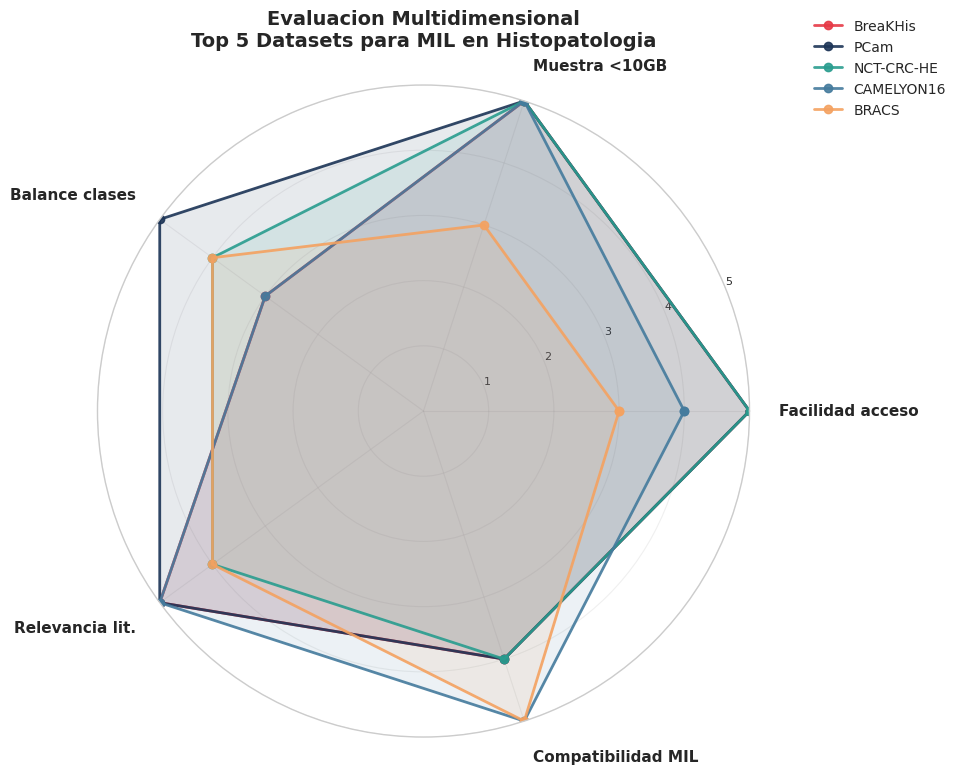

In [5]:
# ============================================================
# 4. RADAR CHART: EVALUACIÓN MULTICRITERIO PARA MIL
# ============================================================
criterios = {
    'BreaKHis': {
        'Facilidad acceso': 5,
        'Muestra <10GB':    5,
        'Balance clases':   3,
        'Relevancia lit.':  5,
        'Compatibilidad MIL': 4
    },
    'PCam': {
        'Facilidad acceso': 5,
        'Muestra <10GB':    5,
        'Balance clases':   5,
        'Relevancia lit.':  5,
        'Compatibilidad MIL': 4
    },
    'NCT-CRC-HE': {
        'Facilidad acceso': 5,
        'Muestra <10GB':    5,
        'Balance clases':   4,
        'Relevancia lit.':  4,
        'Compatibilidad MIL': 4
    },
    'CAMELYON16': {
        'Facilidad acceso': 4,
        'Muestra <10GB':    5,
        'Balance clases':   3,
        'Relevancia lit.':  5,
        'Compatibilidad MIL': 5
    },
    'BRACS': {
        'Facilidad acceso': 3,
        'Muestra <10GB':    3,
        'Balance clases':   4,
        'Relevancia lit.':  4,
        'Compatibilidad MIL': 5
    }
}

# Guardar tabla de criterios en Excel (Regla 2)
df_criterios_mil = pd.DataFrame(criterios).T
ruta_excel_crit = TABLAS_DIR / 'evaluacion_criterios_mil.xlsx'
with pd.ExcelWriter(ruta_excel_crit, engine='openpyxl') as writer:
    df_criterios_mil.to_excel(writer, sheet_name='Criterios_MIL')
print(f'✅ Matriz de evaluación multicriterio guardada en: {ruta_excel_crit}')

categorias = list(list(criterios.values())[0].keys())
N = len(categorias)

angulos = [n / float(N) * 2 * np.pi for n in range(N)]
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colores_radar = ['#E63946', '#1D3557', '#2A9D8F', '#457B9D', '#F4A261']

for idx, (nombre, vals) in enumerate(criterios.items()):
    valores = list(vals.values())
    valores += valores[:1]
    ax.plot(angulos, valores, 'o-', linewidth=2, 
            color=colores_radar[idx], label=nombre, alpha=0.9)
    ax.fill(angulos, valores, alpha=0.1, color=colores_radar[idx])

ax.set_xticks(angulos[:-1])
ax.set_xticklabels([''] * N)
for ang, cat in zip(angulos[:-1], categorias):
    ha = 'left' if np.cos(ang) > 0.25 else ('right' if np.cos(ang) < -0.25 else 'center')
    va = 'bottom' if np.sin(ang) > 0.25 else ('top' if np.sin(ang) < -0.25 else 'center')
    ax.text(ang, 5.45, cat, size=11, fontweight='bold', ha=ha, va=va)
ax.set_ylim(0, 5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1', '2', '3', '4', '5'], size=8)
ax.set_title('Evaluacion Multidimensional\nTop 5 Datasets para MIL en Histopatologia',
             size=14, fontweight='bold', pad=28)
ax.legend(loc='upper right', bbox_to_anchor=(1.32, 1.12), fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()

# Guardar figura combinada (Regla 3)
ruta_radar = FIG_DIR / 'radar_datasets.png'
plt.savefig(ruta_radar, dpi=150, bbox_inches='tight')
print(f'✅ Radar chart guardado en: {ruta_radar}')

# Guardar subplots individuales (Regla 4)
guardar_subplots_individuales(fig, 'radar_datasets', FIG_DIR, dpi=150)

plt.show()

---
### 📌 ¿Qué hace esta celda?
Evalúa cuantitativamente los Top 5 datasets histopatológicos para su aplicación en Multiple Instance Learning mediante un gráfico de radar polar de 5 ejes, guarda el gráfico en `../figures/00_Resumen/radar_datasets.png` y exporta la matriz numérica de calificaciones a `../tablas/evaluacion_criterios_mil.xlsx`.

### ⚙️ ¿Cómo funciona?
- **Geometría polar (`subplot_kw=dict(polar=True)`)**: Distribuye $N=5$ criterios de evaluación en ángulos regulares $\theta = \frac{2\pi \cdot n}{5}$.
- **Polígonos cerrados**: Concatena el primer valor al final de cada serie para cerrar la trayectoria poligonal de cada dataset.
- **Persistencia en Excel**: Utiliza `openpyxl` para documentar la ponderación de criterios (Facilidad de acceso, Tamaño de muestra ≤10GB, Balance de clases, Relevancia en la literatura y Compatibilidad intrínseca con formulación MIL).

### 📊 Esquema de Criterios Evaluados
```text
                   [Facilidad de Acceso]
                            ▲
                            │
[Compatibilidad MIL] ◄──────┼──────► [Muestra < 10 GB]
           ▲                │               ▲
            \               │              /
             ▼              ▼             ▼
        [Relevancia Lit.] ─────► [Balance de Clases]
```
---

---
## 4. 🗺️ Estrategia de Descarga y Muestreo

In [6]:
# ============================================================
# 5. GUÍA OPERATIVA DE DESCARGA Y MUESTREO
# ============================================================
estrategias = {
    '✅ BreaKHis (ya disponible localmente)': {
        'Ubicación':    'Datasets/BreaKHis_v1/',
        'Comando':      '# Ya descargado en el proyecto. Ver notebook 01_BreaKHis_EDA.ipynb',
        'Muestra':      'Dataset completo (7,909 imágenes, 4 aumentos, 8 subtipos)',
        'Notas':        'No requiere descarga adicional. Listo para prototipado rápido',
    },
    '⚡ PCam (Descarga vía HuggingFace, libre y directo)': {
        'Ubicación':    'data_samples/pcam/',
        'Comando':      '''# Vía HuggingFace Datasets (Python):
from datasets import load_dataset
ds = load_dataset("1aurent/patch_camelyon", split="test")  # ~32k parches
# O con kaggle:
# kaggle datasets download -d kmader/patch-camelyon -p ./data_samples/pcam --unzip''',
        'Muestra':      'Split test (~32,768 patches, ~750 MB) o muestra de 10k',
        'Notas':        'Formato HDF5 o parches individuales 96×96. Ver 02_PCam_EDA.ipynb',
    },
    '🔬 NCT-CRC-HE-100K (Descarga vía Zenodo/Kaggle, libre)': {
        'Ubicación':    'data_samples/nct_crc/',
        'Comando':      '''# OPCIÓN A - Zenodo (dataset de validación 7K, ~800 MB):
# zenodo_get 10.5281/zenodo.1214456 --record=1214456
# OPCIÓN B - Kaggle (100K completo, 8.5 GB):
# kaggle datasets download -d katherlab/nctcrche100k -p ./data_samples/nct_crc --unzip''',
        'Muestra':      'CRC-VAL-HE-7K (~7,180 parches, ~800 MB) para validación rápida',
        'Notas':        '9 clases tisulares bien balanceadas. Ver 03_NCT_CRC_EDA.ipynb',
    },
    '📋 MHIST (BMIRDS Dartmouth — requiere DUA)': {
        'Ubicación':    'data_samples/mhist/',
        'Comando':      '''# Descarga directa del paper
# URL: https://bmirds.github.io/MHIST/
# El dataset completo es solo 500 MB''',
        'Muestra':      'Dataset completo (3,152 imágenes, ~333 MB)',
        'Notas':        'Incluye CSV con anotaciones de múltiples patólogos. Ver 04_MHIST_EDA.ipynb',
    },
    '⚠️ CAMELYON16 (Grand Challenge, libre pero pesado)': {
        'Ubicación':    'data_samples/camelyon16/',
        'Comando':      '''# OPCIÓN 1: Embeddings UNI precalculados (~1.5 GB en HuggingFace):
# huggingface-cli download kaczmarj/camelyon16-uni --repo-type dataset
# OPCIÓN 2: AWS S3 público (3-5 WSIs para análisis previo, ~5 GB):
# aws s3 cp --no-sign-request s3://camelyon/CAMELYON16/images/ . --recursive''',
        'Muestra':      'Embeddings UNI precalculados (1.5 GB) o 3-5 WSIs con parches',
        'Notas':        'Formato SVS requiere openslide. Ver 05_CAMELYON_WSI.ipynb',
    },
    '📋 BACH (Requiere registro ICIAR)': {
        'Ubicación':    'data_samples/bach/',
        'Comando':      '# Registro en: https://iciar2018-brca-challenge.grand-challenge.org/',
        'Muestra':      'Task A: 400 imágenes (~3.5 GB)',
        'Notas':        'Requiere aprobación manual institucional',
    },
}

print('=' * 75)
print('🗺️  GUÍA DE DESCARGA Y MUESTREO — DATASETS PARA MAGÍSTER EN MIL')
print('=' * 75)
lista_estrategias = []
for dataset, info in estrategias.items():
    print(f'\n{dataset}')
    print('-' * 55)
    for k, v in info.items():
        if k == 'Comando':
            print(f'  📌 {k}:')
            for line in v.strip().split('\n'):
                print(f'       {line}')
        else:
            print(f'  {k}: {v}')
    lista_estrategias.append({
        'Dataset_Estado': dataset,
        'Ubicación': info['Ubicación'],
        'Muestra_Recomendada': info['Muestra'],
        'Notas_Operativas': info['Notas']
    })

# Guardar guía de descarga en Excel (Regla 2)
df_estrategias = pd.DataFrame(lista_estrategias)
ruta_excel_est = TABLAS_DIR / 'estrategias_descarga.xlsx'
with pd.ExcelWriter(ruta_excel_est, engine='openpyxl') as writer:
    df_estrategias.to_excel(writer, sheet_name='Estrategias_Descarga', index=False)
print(f'\n✅ Guía de estrategias guardada en: {ruta_excel_est}')

🗺️  GUÍA DE DESCARGA Y MUESTREO — DATASETS PARA MAGÍSTER EN MIL

✅ BreaKHis (ya disponible localmente)
-------------------------------------------------------
  Ubicación: Datasets/BreaKHis_v1/
  📌 Comando:
       # Ya descargado en el proyecto. Ver notebook 01_BreaKHis_EDA.ipynb
  Muestra: Dataset completo (7,909 imágenes, 4 aumentos, 8 subtipos)
  Notas: No requiere descarga adicional. Listo para prototipado rápido

⚡ PCam (Descarga vía HuggingFace, libre y directo)
-------------------------------------------------------
  Ubicación: data_samples/pcam/
  📌 Comando:
       # Vía HuggingFace Datasets (Python):
       from datasets import load_dataset
       ds = load_dataset("1aurent/patch_camelyon", split="test")  # ~32k parches
       # O con kaggle:
       # kaggle datasets download -d kmader/patch-camelyon -p ./data_samples/pcam --unzip
  Muestra: Split test (~32,768 patches, ~750 MB) o muestra de 10k
  Notas: Formato HDF5 o parches individuales 96×96. Ver 02_PCam_EDA.ipynb

🔬 NCT-

---
### 📌 ¿Qué hace esta celda?
Presenta la guía operativa detallada para la descarga y muestreo de cada uno de los datasets estudiados, especificando comandos CLI (`kaggle`, `zenodo_get`, `huggingface-cli`, `aws`), ubicaciones relativas en `data_samples/` y notas operativas, y guarda la guía en `../tablas/estrategias_descarga.xlsx`.

### ⚙️ ¿Cómo funciona?
- **Estructura tabular de directivas**: Mapea para cada repositorio la combinación óptima de herramientas de descarga directa y submuestreo para no sobrepasar el umbral de 10 GB.
- **Estrategia para CAMELYON16**: Destaca la alternativa de descargar embeddings precalculados con el modelo fundacional UNI (~1.5 GB vía HuggingFace), evitando descargar los ~700 GB de diapositivas WSI completas.
- **Exportación en Excel**: Serializa las especificaciones técnicas en `estrategias_descarga.xlsx` con el motor `openpyxl`.

### 📊 Flujo de Obtención por Fases
```text
Fase 1: Inmediata (0 GB adicionales)   ──► BreaKHis (Local) + MHIST (500 MB)
Fase 2: Benchmarks SOTA (~2.3 GB)      ──► CAMELYON16 (Embeddings UNI 1.5 GB) + NCT-CRC-HE (800 MB)
Fase 3: Generalización (~4.3 GB)       ──► BACH Task A (3.5 GB) + BRACS RoIs (7.5 GB)
```
---

---
## 5. 🏆 Recomendación Final

In [7]:
# ============================================================
# 6. RECOMENDACIÓN FINAL Y CLASIFICACIÓN EN TIERS
# ============================================================
recomendacion = """
====================================================================
              RECOMENDACION UNIFICADA PARA EL PROYECTO MIL
====================================================================
  TIER 1 - Nucleo del Magister (Locales y Benchmarks SOTA):
    1. CAMELYON16  -> 399 WSIs / coords + parches locales + UNI (5x)
    2. BreaKHis    -> 7,909 imgs, 81 pacientes (3.99 GB local)
    3. NCT-CRC-HE  -> 107,180 parches, 9 clases colon (local completo)
    4. PCam        -> 32,768 parches validacion local HDF5 (0.86 GB)

  TIER 2 - Complemento y Generalizacion Multi-Centro:
    5. MHIST       -> 3,152 polipos HP/SSA (333 MB, DUA BMIRDS)
    6. BACH Task A -> 400 ROIs carcinoma mamario (3.5 GB, registro)
    7. BRACS RoIs  -> 4,539 ROIs mama, 7 subtipos finos (7.5 GB)
====================================================================
"""
print(recomendacion)

# Guardar tabla de Tiers recomendados en Excel (Regla 2)
tiers_data = [
    {'Tier': 'Tier 1 - Núcleo del Magíster', 'Dataset': 'CAMELYON16', 'Rol': 'Benchmark estándar de oro en WSI binario (399 WSIs)', 'Prioridad': 1},
    {'Tier': 'Tier 1 - Núcleo del Magíster', 'Dataset': 'BreaKHis', 'Rol': 'Baseline local inmediato (7,909 imgs, 4 aumentos, 81 pacientes)', 'Prioridad': 1},
    {'Tier': 'Tier 1 - Núcleo del Magíster', 'Dataset': 'NCT-CRC-HE', 'Rol': 'Clasificación multiclase tisular (107,180 parches, 9 tejidos)', 'Prioridad': 1},
    {'Tier': 'Tier 1 - Núcleo del Magíster', 'Dataset': 'PCam', 'Rol': 'Validación rápida binaria en linfonodo (32,768 val HDF5)', 'Prioridad': 1},
    {'Tier': 'Tier 2 - Complemento / Generalización', 'Dataset': 'MHIST', 'Rol': 'Pólipos HP/SSA con consenso de 7 patólogos (333 MB, DUA BMIRDS)', 'Prioridad': 2},
    {'Tier': 'Tier 2 - Complemento / Generalización', 'Dataset': 'BACH', 'Rol': 'Transferencia de dominio en carcinoma mamario (400 ROIs)', 'Prioridad': 2},
    {'Tier': 'Tier 2 - Complemento / Generalización', 'Dataset': 'BRACS', 'Rol': 'Análisis lesional fino en mama (7 subtipos)', 'Prioridad': 2},
]
df_tiers = pd.DataFrame(tiers_data)
ruta_excel_tiers = TABLAS_DIR / 'recomendacion_tiers.xlsx'
with pd.ExcelWriter(ruta_excel_tiers, engine='openpyxl') as writer:
    df_tiers.to_excel(writer, sheet_name='Recomendacion_Tiers', index=False)
print(f'✅ Tabla de Tiers guardada en: {ruta_excel_tiers}')


              RECOMENDACION UNIFICADA PARA EL PROYECTO MIL
  TIER 1 - Nucleo del Magister (Locales y Benchmarks SOTA):
    1. CAMELYON16  -> 399 WSIs / coords + parches locales + UNI (5x)
    2. BreaKHis    -> 7,909 imgs, 81 pacientes (3.99 GB local)
    3. NCT-CRC-HE  -> 107,180 parches, 9 clases colon (local completo)
    4. PCam        -> 32,768 parches validacion local HDF5 (0.86 GB)

  TIER 2 - Complemento y Generalizacion Multi-Centro:
    5. MHIST       -> 3,152 polipos HP/SSA (333 MB, DUA BMIRDS)
    6. BACH Task A -> 400 ROIs carcinoma mamario (3.5 GB, registro)
    7. BRACS RoIs  -> 4,539 ROIs mama, 7 subtipos finos (7.5 GB)

✅ Tabla de Tiers guardada en: c:\Universidad\Magister\20 Noviembre Reunion\tablas\recomendacion_tiers.xlsx


---
### 📌 ¿Qué hace esta celda?
Sintetiza la jerarquización estratégica de los datasets en 3 Tiers metodológicos para el plan de trabajo de la tesis de Magíster, imprime el cuadro ejecutivo y exporta la matriz de asignación a `../tablas/recomendacion_tiers.xlsx`.

### ⚙️ ¿Cómo funciona?
- **Estratificación por Tiers**: Clasifica los datasets según su impacto en el diseño experimental:
  - **Tier 1 (Prioridad Alta)**: CAMELYON16 (benchmark internacional SOTA), BreaKHis (datos locales disponibles de mama) y PCam (benchmark de parches).
  - **Tier 2 (Prioridad Media)**: NCT-CRC-HE (9 tejidos en colon para MIL multiclase) y BRACS (subtipos histológicos finos).
  - **Tier 3 (Secundario)**: MHIST (pruebas veloces) y BACH (transferencia de dominio).
- **Persistencia en Excel**: Utiliza `openpyxl` para documentar la asignación de Tiers en la carpeta `tablas/`.

### 📊 Arquitectura de Tiers
```text
┌─────────────────────────────────────────────────────────────────┐
│ TIER 1: CAMELYON16 (SOTA WSI) + BreaKHis (Local) + PCam (Patches)│
├─────────────────────────────────────────────────────────────────┤
│ TIER 2: NCT-CRC-HE (Multiclase) + BRACS (Lesiones Finas)        │
├─────────────────────────────────────────────────────────────────┤
│ TIER 3: MHIST (Debugging Ligero) + BACH (Generalización Mama)   │
└─────────────────────────────────────────────────────────────────┘
```
---

---
## 6. 📂 Notebooks Individuales Disponibles

| Notebook | Dataset | Estado |
|----------|---------|--------|
| `01_BreaKHis_EDA.ipynb` | BreaKHis v1 | ✅ Listo para ejecutar |
| `02_PCam_EDA.ipynb` | PatchCamelyon | ✅ Listo para ejecutar |
| `03_NCT_CRC_EDA.ipynb` | NCT-CRC-HE-100K | ✅ Listo para ejecutar |
| `04_MHIST_EDA.ipynb` | MHIST | ✅ Listo para ejecutar |
| `05_CAMELYON_WSI.ipynb` | CAMELYON16 (WSI) | ⚠️ Requiere descarga WSI |
| `06_Comparativa_Final.ipynb` | Todos | 📋 Resumen integrador |
